# Age at first and last work
At what age do individuals produce their first and their last work, and what is the best way to impute these years from the birth year?

In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from style import *

DB_PATH = '../data/cultura/humans_clean_non_enriched_v3.duckdb'
ENRICHED_DB_PATH = '../data/cultura/cultura_enriched_v3.2.duckdb'

MID_DECADE = 5
LIFETIME_LIMIT = 100
CENTURY = 100
FIRST_CENTURY, LAST_CENTURY = -800, 1800
LAST_YEAR = 1899
AGE_MIN, AGE_MAX = 10, 100
MIN_INDIVIDUALS = 10
SEED = 42
TRAIN_SHARE = 0.8
WITHIN = 10
MEASURES = {
    'first': {'label': 'first work', 'random': (15, 60)},
    'last': {'label': 'last work', 'random': (20, 80)},
}
MODELS = {'century': ['century'], 'meta occupation': ['meta_occupation'], 'century × meta occupation': ['century', 'meta_occupation']}
MODEL_COLORS = {'random': LIGHT_GREY, 'global': GREY, 'century': BLUE, 'meta occupation': ORANGE, 'century × meta occupation': GREEN}
GROUPS = ['All', *OCCUPATION_COLORS, 'Other']
GROUP_COLORS = {'All': MAIN_LINE_COLOR, **OCCUPATION_COLORS, 'Other': GREY}

pl.Config.set_tbl_rows(40)
apply_style()

connection = duckdb.connect(DB_PATH, read_only=True)
connection.execute(f"ATTACH '{ENRICHED_DB_PATH}' AS enriched (READ_ONLY)")

## Load the data
Cleaned work dates, as in notebook 03: a work's date is its inception, else its publication, precise to the year or decade (a decade counts as its middle year), and it must fit the individual's life (between birth and death, or birth + 100 when only the birth is known).

In [2]:
connection.execute(f'''
    CREATE OR REPLACE TEMP TABLE clean_work AS
    WITH lifetime AS (
        SELECT entity.qid AS qid,
               list_min([date.year FOR date IN birth_date IF date.precision IN ('day', 'month', 'year', 'decade')]) AS birth_year,
               list_min([date.year FOR date IN death_date IF date.precision IN ('day', 'month', 'year', 'decade')]) AS death_year
        FROM individual
    ),
    dated AS (
        SELECT DISTINCT individual_work.qid, individual_work.work_qid,
               CASE WHEN work.inception.precision IN ('day', 'month', 'year', 'decade') THEN work.inception.year END AS inception_year,
               CASE WHEN work.publication_date.precision IN ('day', 'month', 'year', 'decade') THEN work.publication_date.year END AS publication_year,
               work.inception.precision AS inception_precision,
               work.publication_date.precision AS publication_precision
        FROM individual_work
        JOIN work ON work.entity.qid = individual_work.work_qid
    ),
    dated_with_source AS (
        SELECT qid, work_qid,
               coalesce(inception_year, publication_year) AS year,
               CASE WHEN inception_year IS NOT NULL THEN 'inception' ELSE 'publication' END AS source,
               CASE WHEN inception_year IS NOT NULL THEN inception_precision ELSE publication_precision END AS precision
        FROM dated
        WHERE coalesce(inception_year, publication_year) IS NOT NULL
    ),
    first_inception AS (
        SELECT qid, min(year) AS first_inception_year
        FROM dated_with_source
        WHERE source = 'inception'
        GROUP BY qid
    ),
    kept AS (
        SELECT dated_with_source.*, lifetime.birth_year, lifetime.death_year
        FROM dated_with_source
        JOIN lifetime ON lifetime.qid = dated_with_source.qid
        LEFT JOIN first_inception ON first_inception.qid = dated_with_source.qid
        WHERE (first_inception.qid IS NOT NULL OR lifetime.birth_year IS NOT NULL OR lifetime.death_year IS NOT NULL)
          AND CASE
              WHEN lifetime.birth_year IS NOT NULL OR lifetime.death_year IS NOT NULL THEN
                  dated_with_source.year BETWEEN coalesce(lifetime.birth_year, lifetime.death_year - {LIFETIME_LIMIT})
                                             AND coalesce(lifetime.death_year, lifetime.birth_year + {LIFETIME_LIMIT})
              WHEN dated_with_source.source = 'publication' THEN
                  abs(dated_with_source.year - first_inception.first_inception_year) <= {LIFETIME_LIMIT}
              ELSE TRUE
          END
    ),
    inception_only_too_long AS (
        SELECT qid
        FROM kept
        WHERE birth_year IS NULL AND death_year IS NULL
        GROUP BY qid
        HAVING bool_and(source = 'inception') AND max(year) - min(year) > {LIFETIME_LIMIT}
    )
    SELECT *
    FROM kept
    WHERE qid NOT IN (SELECT qid FROM inception_only_too_long)
''')
clean_counts = connection.execute("SELECT count(DISTINCT qid) AS individuals, count(*) AS work_dates FROM clean_work").pl()
print(f"{clean_counts['individuals'][0]:,} individuals keep {clean_counts['work_dates'][0]:,} cleaned work dates")

584,893 individuals keep 9,481,624 cleaned work dates


### First and last work, birth and meta occupation
The main meta occupation is the most frequent one among the individual's occupations ("Other" when none).

In [3]:
works = connection.execute(f'''
    WITH ends AS (
        SELECT qid, any_value(birth_year) AS birth_year,
               min(CASE WHEN precision = 'decade' THEN year + {MID_DECADE} ELSE year END) AS first_year,
               max(CASE WHEN precision = 'decade' THEN year + {MID_DECADE} ELSE year END) AS last_year,
               count(*) AS works
        FROM clean_work
        WHERE birth_year IS NOT NULL
        GROUP BY qid
    ),
    held AS (
        SELECT individual.entity.qid AS qid,
               unnest(individual.occupation).entity.qid AS occupation_qid,
               generate_subscripts(individual.occupation, 1) AS position
        FROM individual
        JOIN ends ON ends.qid = individual.entity.qid
    ),
    counted AS (
        SELECT held.qid, occupation.meta_occupation, count(*) AS occupations, min(held.position) AS first_position
        FROM held
        JOIN enriched.occupation AS occupation ON occupation.entity.qid = held.occupation_qid
        WHERE occupation.meta_occupation IS NOT NULL
        GROUP BY ALL
    ),
    main_meta_occupation AS (
        SELECT qid, meta_occupation
        FROM counted
        QUALIFY row_number() OVER (PARTITION BY qid ORDER BY occupations DESC, first_position) = 1
    )
    SELECT ends.*, coalesce(main_meta_occupation.meta_occupation, 'Other') AS meta_occupation
    FROM ends
    LEFT JOIN main_meta_occupation ON main_meta_occupation.qid = ends.qid
''').pl().with_columns(
    (pl.col('first_year') - pl.col('birth_year')).alias('first_age'),
    (pl.col('last_year') - pl.col('birth_year')).alias('last_age'),
    (pl.col('birth_year') // CENTURY * CENTURY).alias('century'),
)
assert works['qid'].is_unique().all()
print(f'{works.height:,} individuals with a birth year and at least one cleaned work')
works = works.filter(pl.col('century').is_between(FIRST_CENTURY, LAST_CENTURY) & (pl.col('birth_year') <= LAST_YEAR))
print(f'{works.height:,} born from {FIRST_CENTURY} to {LAST_YEAR}')
works = works.filter(pl.col('first_age').is_between(AGE_MIN, AGE_MAX) & pl.col('last_age').is_between(AGE_MIN, AGE_MAX))
print(f'{works.height:,} with first and last works between {AGE_MIN} and {AGE_MAX}: the group used below')
assert (works['first_age'] <= works['last_age']).all()
works.sample(5, seed=SEED)

557,730 individuals with a birth year and at least one cleaned work
114,425 born from -800 to 1899
113,151 with first and last works between 10 and 100: the group used below


qid,birth_year,first_year,last_year,works,meta_occupation,first_age,last_age,century
str,i64,i64,i64,i64,str,i64,i64,i64
"""Q69676""",1849,1887,1887,1,"""Culture""",38,38,1800
"""Q450430""",1805,1844,1849,6,"""Leadership""",39,44,1800
"""Q15830332""",1845,1880,1880,1,"""Other""",35,35,1800
"""Q11944435""",1887,1926,1939,2,"""Culture""",39,52,1800
"""Q5613525""",1662,1732,1732,1,"""Leadership""",70,70,1600


## Methods and plots
A random 80% of the group learns the mean age at the work (train); for the other 20% (test), the work is imputed as birth year + that mean, and is good when within 10 years of the true one. A group with fewer than 10 training individuals takes the global mean. The century is the century of birth. Models:

- **random**: an age drawn at random (15–60 for the first work, 20–80 for the last).
- **global**: all training individuals.
- **century**, **meta occupation**, **century × meta occupation**: the training individuals of the same group.

Each score is computed in every century of birth (with at least 10 test individuals), then averaged with every century weighing the same. In the box plots: median in colour, quartiles in grey, mean as a diamond.

In [4]:
shuffled = works.sort('qid').sample(fraction=1, shuffle=True, seed=SEED)
cut = int(TRAIN_SHARE * shuffled.height)
train, test = shuffled[:cut], shuffled[cut:]
assert train.height + test.height == works.height and test.join(train, on='qid').height == 0
print(f'train: {train.height:,}, test: {test.height:,}')


def century_label(start):
    end = min(start + CENTURY - 1, LAST_YEAR)
    return f'{-start}–{-end} BC' if end < 0 else f'{start}–{end}'


def impute(measure):
    age, year = f'{measure}_age', f'{measure}_year'
    low, high = MEASURES[measure]['random']
    global_mean = train[age].mean()
    print(f'global mean: {global_mean:.1f} years')
    base = test.select('qid', 'century', 'meta_occupation', 'birth_year', pl.col(year).alias('true year'))
    models = [
        base.with_columns(pl.lit('random').alias('model'), pl.Series('age', np.random.default_rng(SEED).integers(low, high + 1, base.height)).cast(pl.Float64)),
        base.with_columns(pl.lit('global').alias('model'), pl.lit(global_mean).alias('age')),
    ]
    for model, keys in MODELS.items():
        means = train.group_by(keys).agg(pl.len().alias('train individuals'), pl.col(age).mean().alias('age')).filter(pl.col('train individuals') >= MIN_INDIVIDUALS)
        joined = base.join(means, on=keys, how='left')
        print(f"{model}: {joined['age'].null_count():,} test individuals take the global mean")
        models.append(joined.select(*base.columns, pl.lit(model).alias('model'), pl.col('age').fill_null(global_mean)))
    return pl.concat(models).with_columns(
        (pl.col('birth_year') + pl.col('age').round()).cast(pl.Int64).alias('imputed year'),
    ).with_columns((pl.col('imputed year') - pl.col('true year')).alias('error'))


def model_scores(imputed):
    per_century = (
        imputed.group_by('model', 'century', maintain_order=True).agg(
            pl.len().alias('individuals'),
            *[(100 * (pl.col('error').abs() <= years).mean()).alias(f'% within {years} years') for years in (5, WITHIN)],
            pl.col('error').abs().mean().alias('mean absolute error'),
            pl.col('error').abs().median().alias('median absolute error'),
        )
        .filter(pl.col('individuals') >= MIN_INDIVIDUALS)
        .sort('century')
    )
    result = (
        per_century.group_by('model')
        .agg(pl.col('% within 5 years', f'% within {WITHIN} years', 'mean absolute error', 'median absolute error').mean().name.prefix('average of centuries, '))
        .sort(pl.col('model').replace_strict(list(MODEL_COLORS), list(range(len(MODEL_COLORS)))))
    )
    return per_century, result


def plot_models(per_century, measure):
    fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
    for model, color in MODEL_COLORS.items():
        rows = per_century.filter(pl.col('model') == model)
        ax.plot(rows['century'], rows[f'% within {WITHIN} years'], color=color, linewidth=2, marker='o', markersize=4, label=model)
    tested = per_century.group_by('century').agg(pl.col('individuals').first(), pl.col(f'% within {WITHIN} years').max()).sort('century')
    for century, tested_individuals, top in tested.iter_rows():
        ax.annotate(f'{tested_individuals:,}', (century, top), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=9, rotation=90, va='bottom')
    ax.set_xticks(tested['century'].to_list())
    ax.set_xticklabels([century_label(start) for start in tested['century']], rotation=60, ha='right', fontsize=14)
    ax.set_ylim(0, 100)
    ax.set_ylabel(f"% within {WITHIN} years of the true {MEASURES[measure]['label']}")
    ax.set_xlabel('Century of birth')
    ax.grid(axis='x', visible=False)
    ax.legend(loc='upper right', ncols=3)
    plt.tight_layout()
    plt.show()

train: 90,520, test: 22,631


In [5]:
def box_stats(frame, column, by):
    return (
        frame.group_by(by)
        .agg(
            pl.len().alias('individuals'),
            pl.col(column).quantile(0.25, 'linear').alias('low'),
            pl.col(column).median().alias('median'),
            pl.col(column).quantile(0.75, 'linear').alias('high'),
            pl.col(column).mean().round(1).alias('mean'),
        )
        .filter(pl.col('individuals') >= MIN_INDIVIDUALS)
        .sort(by)
    )


def group_stats(column):
    stats = pl.concat([
        box_stats(works.with_columns(pl.lit('All').alias('meta_occupation')), column, 'meta_occupation'),
        box_stats(works, column, 'meta_occupation'),
    ])
    return stats.sort(pl.col('meta_occupation').replace_strict(GROUPS, list(range(len(GROUPS)))))


def draw_boxes(ax, values, positions, width, color, stats, mean_labels=True):
    ax.boxplot(values, positions=positions, widths=width, showfliers=False, patch_artist=True,
               boxprops=dict(facecolor=color, alpha=BAND_ALPHA, edgecolor=color),
               medianprops=dict(color=color, linewidth=2), whiskerprops=dict(color=color), capprops=dict(color=color))
    for x, row in zip(positions, stats.iter_rows(named=True)):
        ax.annotate(f"{row['median']:.0f}", (x + width * 0.55, row['median']), ha='left', va='center', fontsize=POINT_LABEL_FONTSIZE, color=color)
        for q in (row['low'], row['high']):
            ax.annotate(f'{q:.0f}', (x + width * 0.55, q), ha='left', va='center', fontsize=POINT_LABEL_FONTSIZE - 2, color=MUTED_TEXT)
        ax.plot(x, row['mean'], marker='D', markersize=5, color='white', markeredgecolor=TEXT, zorder=3)
        if mean_labels:
            ax.annotate(f"{row['mean']:.1f}", (x - width * 0.55, row['mean']), ha='right', va='center', fontsize=POINT_LABEL_FONTSIZE - 2, color=TEXT)


def plot_centuries(ax, frame, column, color):
    stats = box_stats(frame, column, 'century')
    starts = stats['century'].to_list()
    x = np.array(starts) + CENTURY / 2
    draw_boxes(ax, [frame.filter(pl.col('century') == start)[column].to_numpy() for start in starts], x, CENTURY * 0.5, color, stats, mean_labels=False)
    ax.set_xticks(x)
    ax.set_xticklabels([century_label(start) for start in starts], rotation=45, ha='right')
    ax.set_xlim(starts[0] - CENTURY / 2, starts[-1] + 1.5 * CENTURY)
    ax.set_ylim(0, AGE_MAX + 25)
    ax.set_yticks(range(0, AGE_MAX + 1, 20))
    ax.grid(axis='y')
    for xi, n in zip(x, stats['individuals']):
        ax.text(xi, AGE_MAX + 3, f'{n:,}', rotation=90, ha='center', va='bottom', fontsize=POINT_LABEL_FONTSIZE - 2, color=MUTED_TEXT)


def figure_groups(measure):
    column = f'{measure}_age'
    stats = group_stats(column)
    fig, ax = plt.subplots(figsize=FIGSIZE)
    for i, row in enumerate(stats.iter_rows(named=True)):
        group = row['meta_occupation']
        values = works if group == 'All' else works.filter(pl.col('meta_occupation') == group)
        draw_boxes(ax, [values[column].to_numpy()], [i], 0.5, GROUP_COLORS[group], stats[i])
    ax.set_xticks(range(stats.height))
    ax.set_xticklabels([f"{row['meta_occupation']}\n(n = {row['individuals']:,})" for row in stats.iter_rows(named=True)])
    ax.set_xlim(-0.7, stats.height - 0.3)
    ax.set_ylim(0, AGE_MAX)
    ax.set_ylabel(f"Age at {MEASURES[measure]['label']} (years)")
    ax.grid(axis='y')
    plt.tight_layout()
    plt.show()


def figure_centuries(measure):
    fig, ax = plt.subplots(figsize=(20, 7))
    plot_centuries(ax, works, f'{measure}_age', MAIN_LINE_COLOR)
    ax.set_xlabel('Century of birth')
    ax.set_ylabel(f"Age at {MEASURES[measure]['label']} (years)")
    plt.tight_layout()
    plt.show()


def figure_occupation_centuries(measure):
    fig, axes = plt.subplots(2, 2, figsize=(20, 12), sharey=True)
    for ax, (occupation, color) in zip(axes.flat, OCCUPATION_COLORS.items()):
        ax.text(0.02, 0.98, occupation, transform=ax.transAxes, fontsize=PANEL_LABEL_FONTSIZE, color=color, va='top', fontweight='bold')
        plot_centuries(ax, works.filter(pl.col('meta_occupation') == occupation), f'{measure}_age', color)
    for ax in axes[-1, :]:
        ax.set_xlabel('Century of birth')
    for ax in axes[:, 0]:
        ax.set_ylabel(f"Age at {MEASURES[measure]['label']} (years)")
    plt.tight_layout()
    plt.show()

## 1. Age at first work

### Which method best imputes the year of the first work?

In [6]:
imputed_first = impute('first')
per_century_first, result_first = model_scores(imputed_first)
imputed_first.sample(5, seed=SEED)

global mean: 39.3 years
century: 8 test individuals take the global mean
meta occupation: 0 test individuals take the global mean
century × meta occupation: 51 test individuals take the global mean


qid,century,meta_occupation,birth_year,true year,model,age,imputed year,error
str,i64,str,i64,i64,str,f64,i64,i64
"""Q16595525""",1800,"""Culture""",1828,1885,"""century × meta occupation""",37.422183,1865,-20
"""Q29017776""",1800,"""Culture""",1845,1899,"""global""",39.326745,1884,-15
"""Q55768448""",1800,"""Other""",1854,1926,"""century × meta occupation""",44.5112,1899,-27
"""Q15303873""",1800,"""Leadership""",1816,1882,"""meta occupation""",46.122945,1862,-20
"""Q360094""",1400,"""Leadership""",1434,1458,"""meta occupation""",46.122945,1480,22


### Table: accuracy of the methods, first work

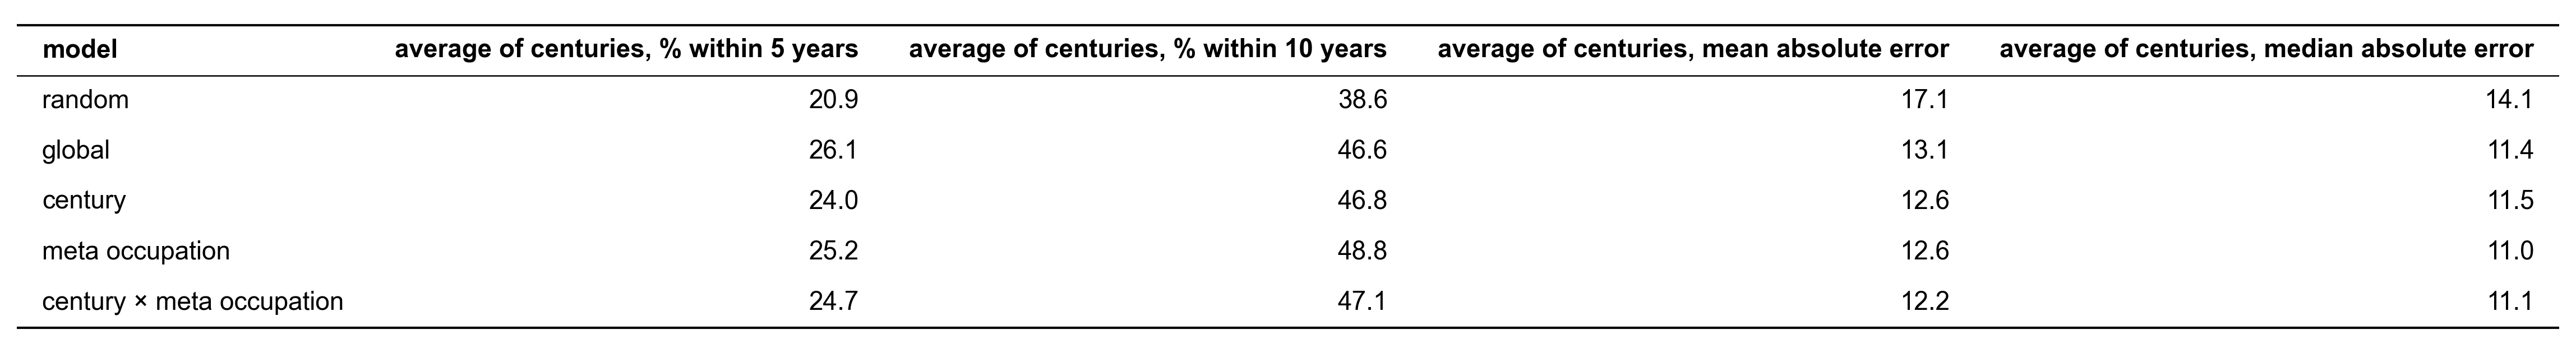

In [7]:
show_table(result_first, decimals=1)

### Figure: % of first works within 10 years per century of birth
Number of test individuals above each century.

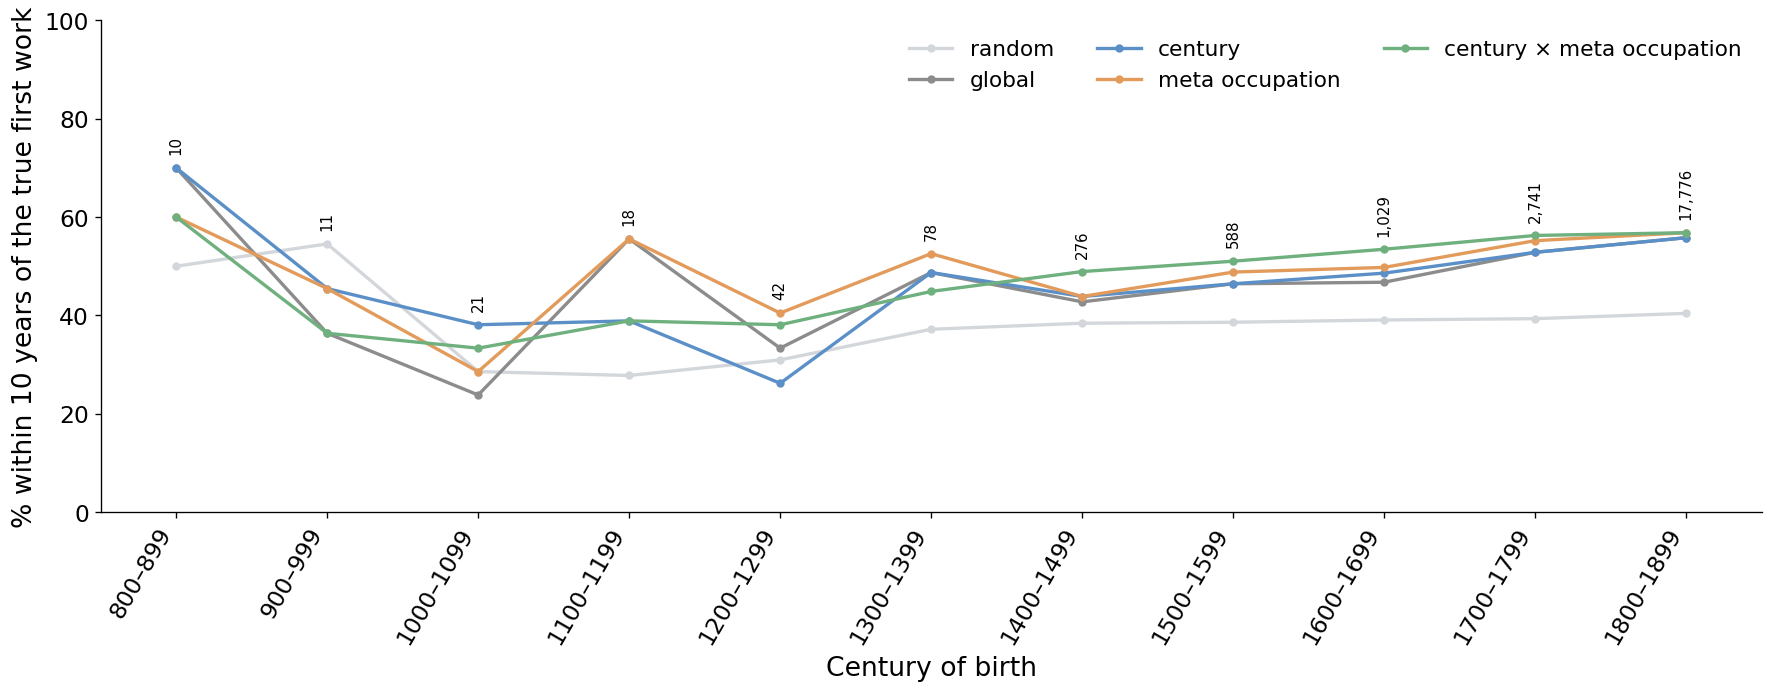

In [8]:
plot_models(per_century_first, 'first')

### Table: age at first work, all individuals and by meta occupation

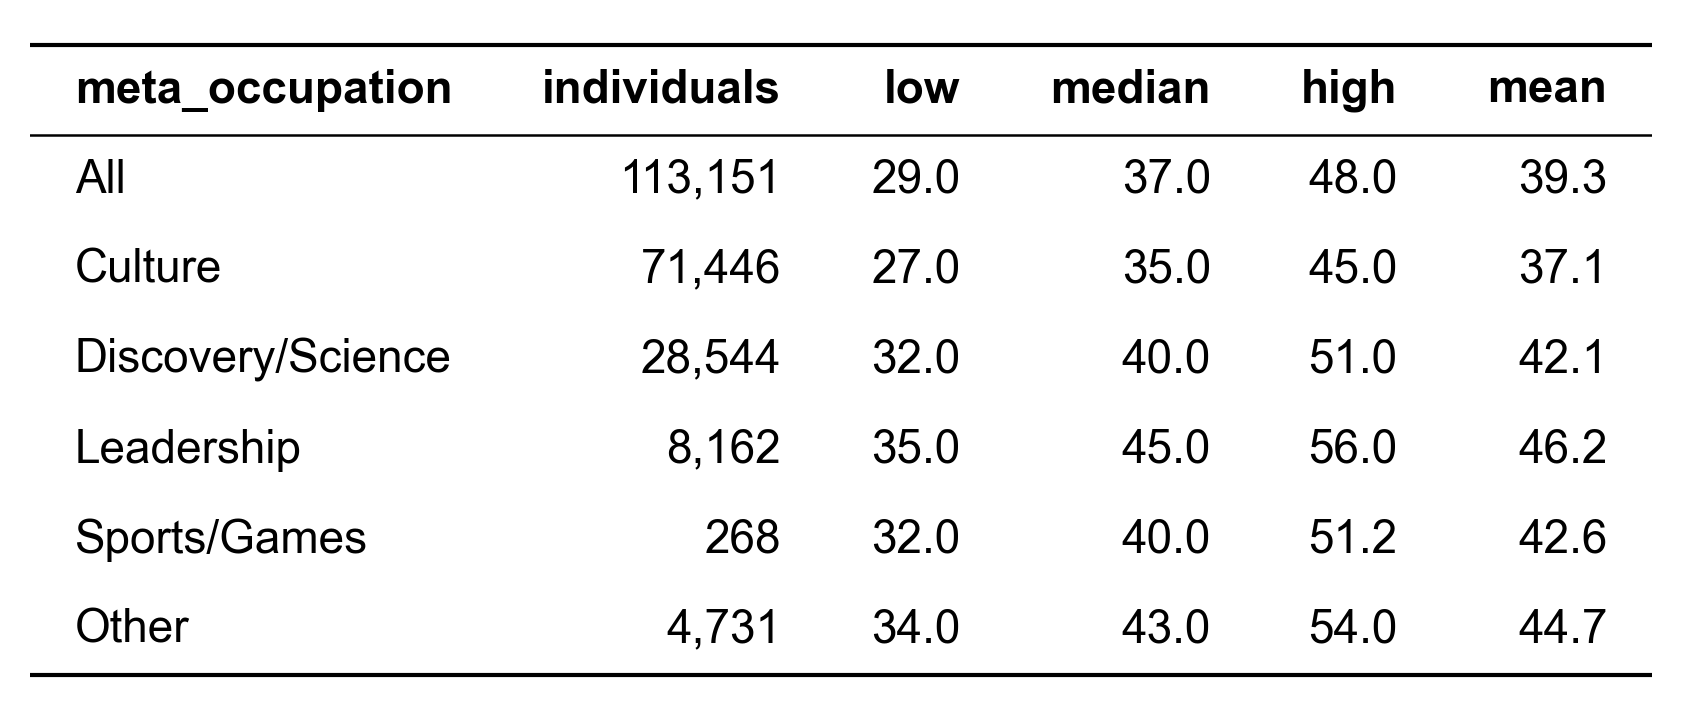

In [9]:
show_table(group_stats('first_age'), decimals=1)

### Figure: age at first work, all individuals and by meta occupation

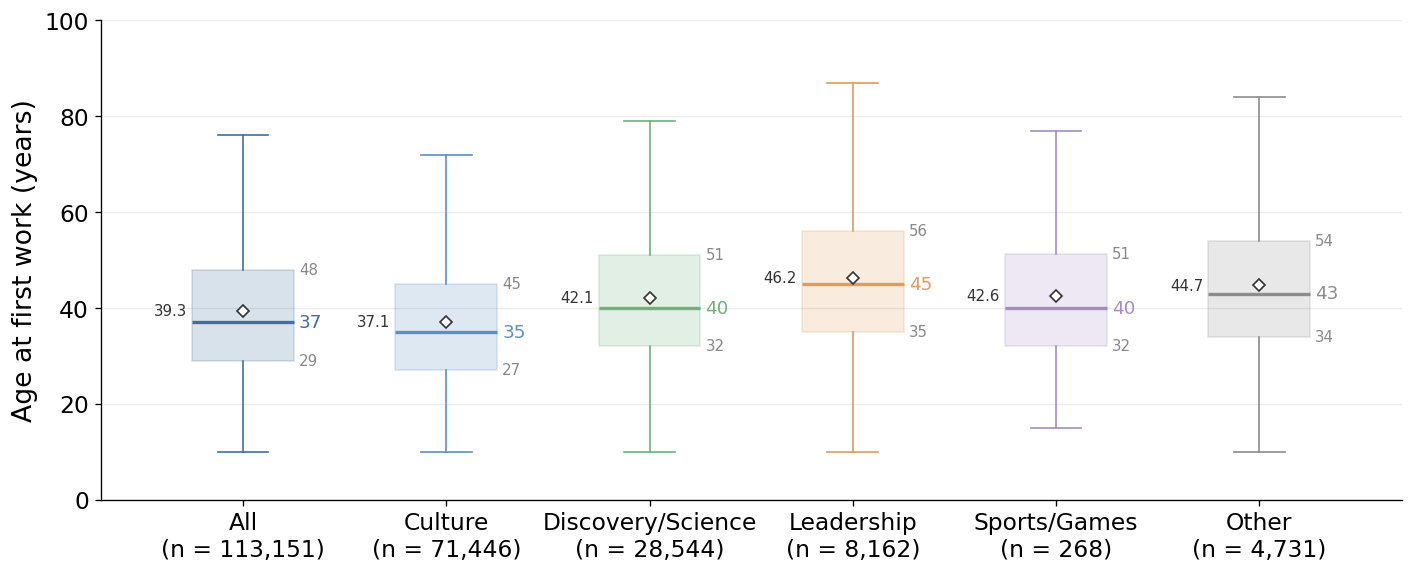

In [10]:
figure_groups('first')

### Table: age at first work per century of birth

In [11]:
box_stats(works, 'first_age', 'century')

century,individuals,low,median,high,mean
i64,u32,f64,f64,f64,f64
-500,11,34.0,39.0,48.5,40.7
-400,16,31.75,42.5,52.25,43.1
-100,16,34.0,43.0,57.5,46.4
0,16,42.25,51.5,58.25,48.4
100,14,35.5,40.5,47.5,45.9
200,15,35.0,41.0,52.5,43.2
300,27,33.0,39.0,48.5,43.3
400,16,33.75,42.0,51.75,43.8
500,36,41.25,53.0,60.75,51.2


### Figure: age at first work per century of birth
Individuals above each century; centuries with fewer than 10 individuals are left out.

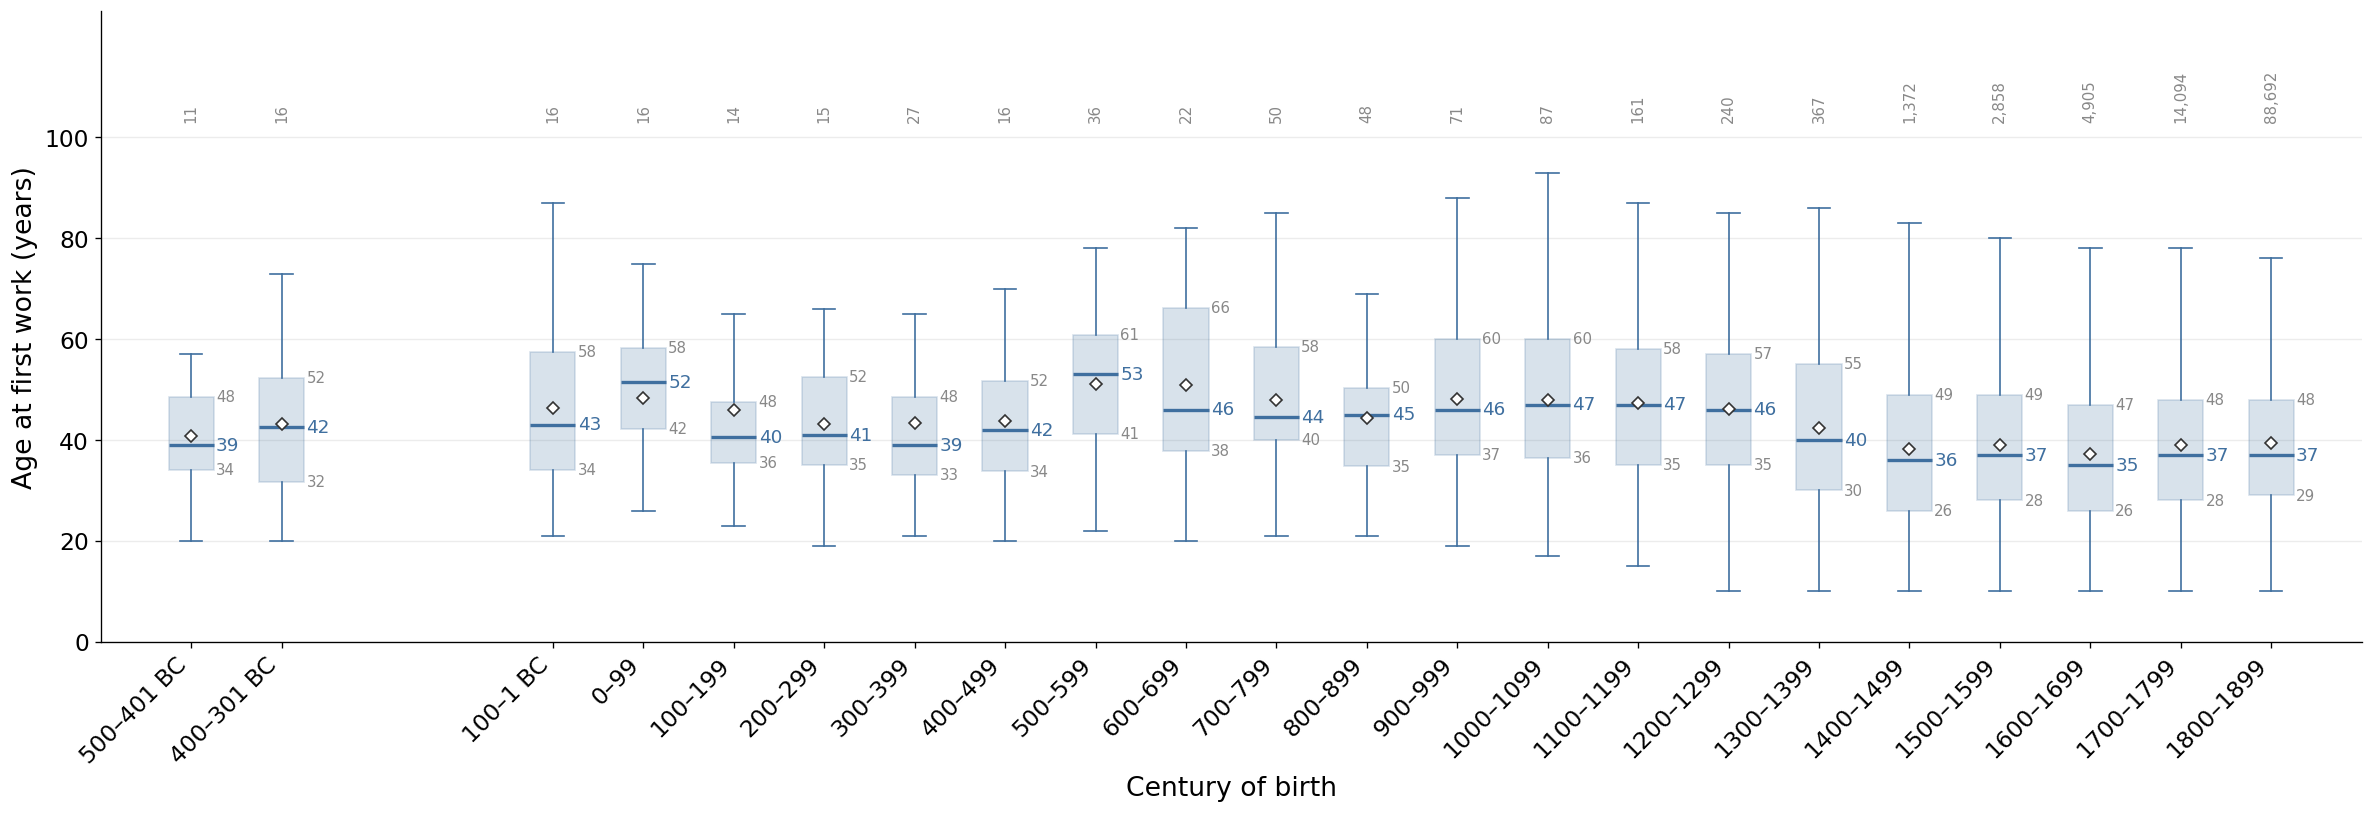

In [12]:
figure_centuries('first')

### Table: age at first work per century of birth and meta occupation
The values used by the century × meta occupation model.

In [13]:
box_stats(works.filter(pl.col('meta_occupation').is_in(list(OCCUPATION_COLORS))), 'first_age', ['meta_occupation', 'century'])

meta_occupation,century,individuals,low,median,high,mean
str,i64,u32,f64,f64,f64,f64
"""Culture""",500,12,36.5,54.0,61.25,50.2
"""Culture""",700,18,36.25,43.0,47.25,42.8
"""Culture""",800,10,33.25,43.0,45.0,41.4
"""Culture""",900,20,34.25,41.5,57.75,47.0
"""Culture""",1000,28,32.0,44.5,54.25,44.1
"""Culture""",1100,69,32.0,40.0,55.0,43.4
"""Culture""",1200,109,33.0,44.0,55.0,44.1
"""Culture""",1300,216,27.0,37.0,49.25,39.4
"""Culture""",1400,973,25.0,32.0,42.0,34.6


### Figure: age at first work per century of birth, by meta occupation

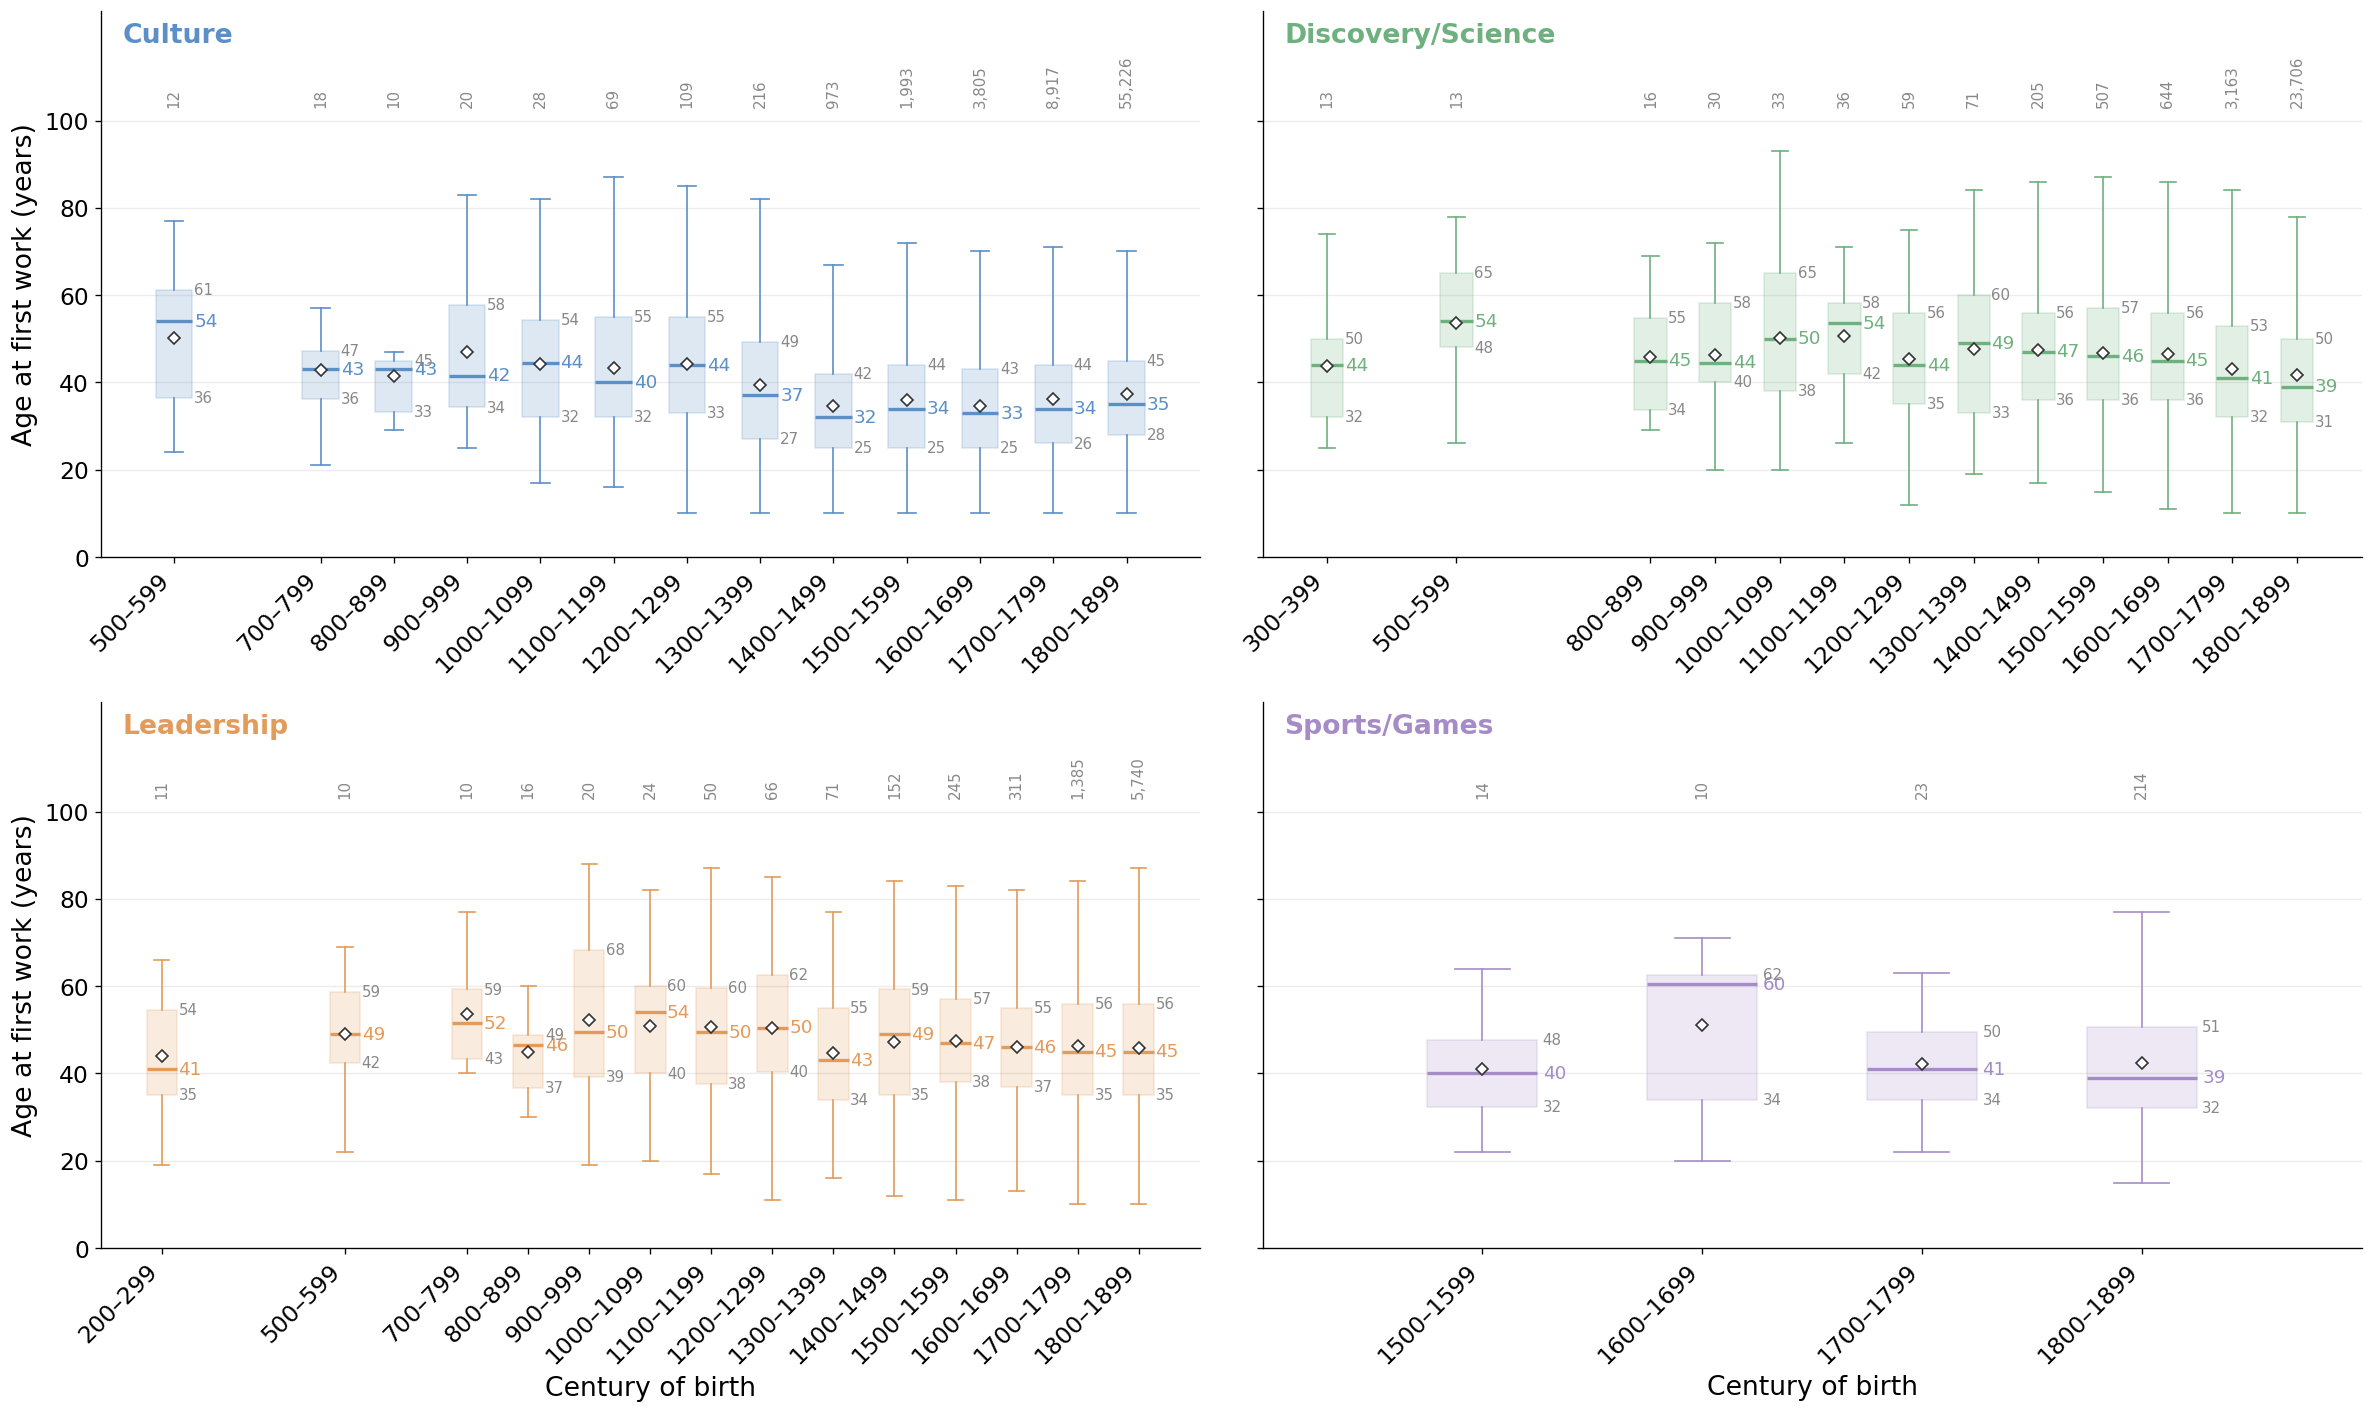

In [14]:
figure_occupation_centuries('first')

## 2. Age at last work

### Which method best imputes the year of the last work?

In [15]:
imputed_last = impute('last')
per_century_last, result_last = model_scores(imputed_last)
imputed_last.sample(5, seed=SEED)

global mean: 49.5 years
century: 8 test individuals take the global mean
meta occupation: 0 test individuals take the global mean
century × meta occupation: 51 test individuals take the global mean


qid,century,meta_occupation,birth_year,true year,model,age,imputed year,error
str,i64,str,i64,i64,str,f64,i64,i64
"""Q16595525""",1800,"""Culture""",1828,1885,"""century × meta occupation""",48.651701,1877,-8
"""Q29017776""",1800,"""Culture""",1845,1899,"""global""",49.473011,1894,-5
"""Q55768448""",1800,"""Other""",1854,1926,"""century × meta occupation""",49.099632,1903,-23
"""Q15303873""",1800,"""Leadership""",1816,1885,"""meta occupation""",50.37452,1866,-19
"""Q360094""",1400,"""Leadership""",1434,1463,"""meta occupation""",50.37452,1484,21


### Table: accuracy of the methods, last work

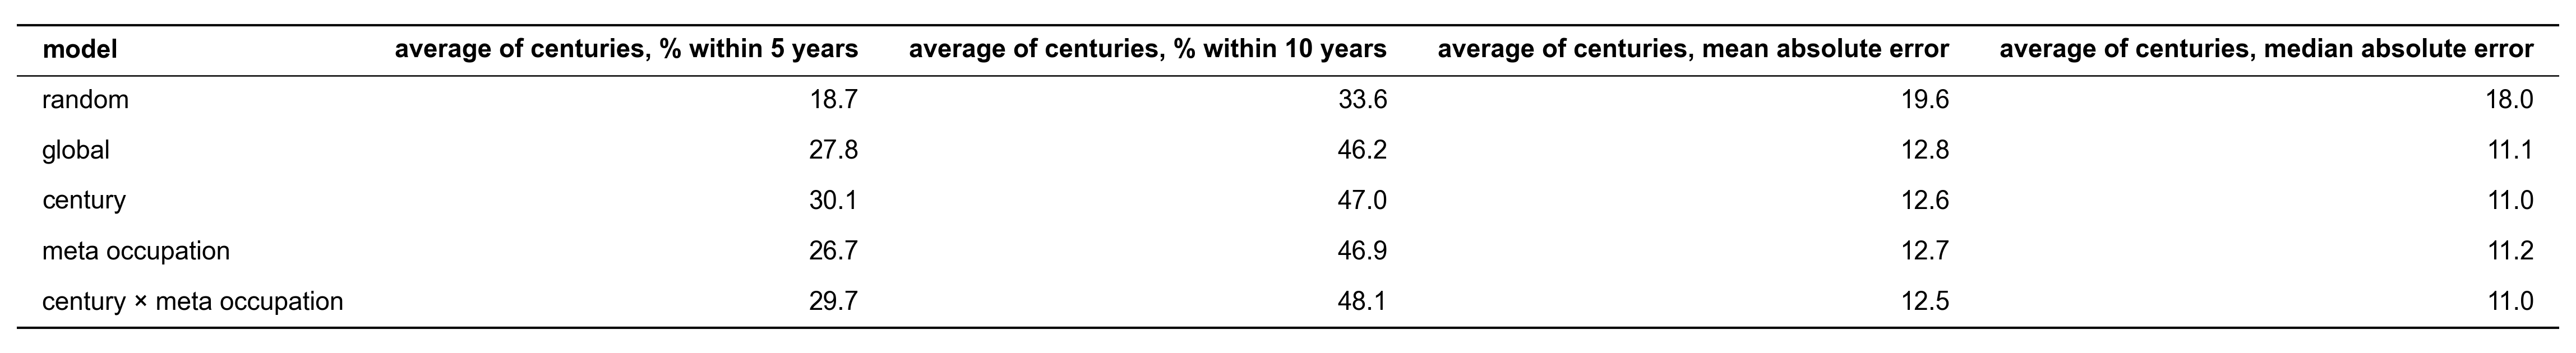

In [16]:
show_table(result_last, decimals=1)

### Figure: % of last works within 10 years per century of birth
Number of test individuals above each century.

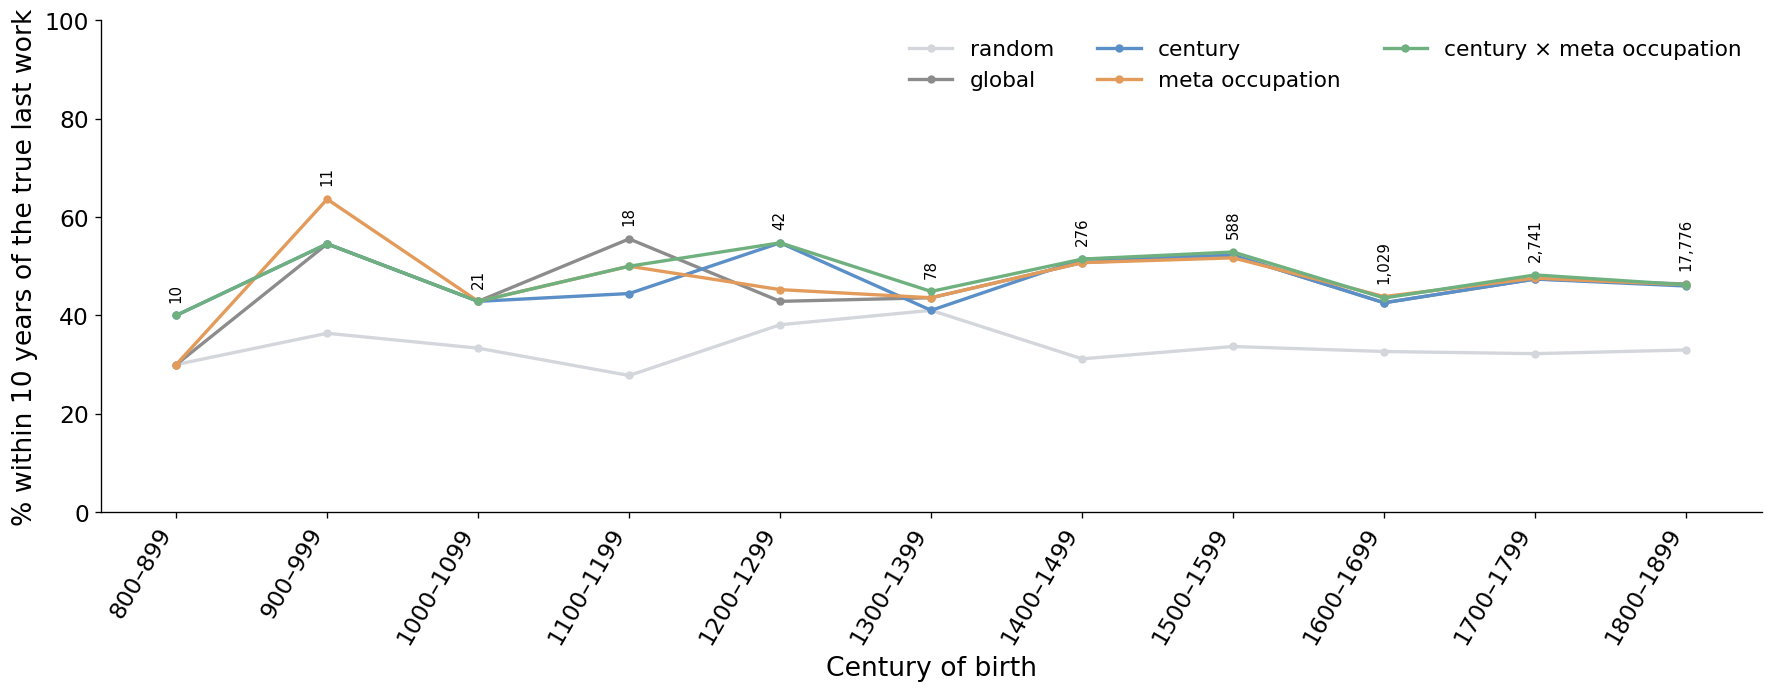

In [17]:
plot_models(per_century_last, 'last')

### Table: age at last work, all individuals and by meta occupation

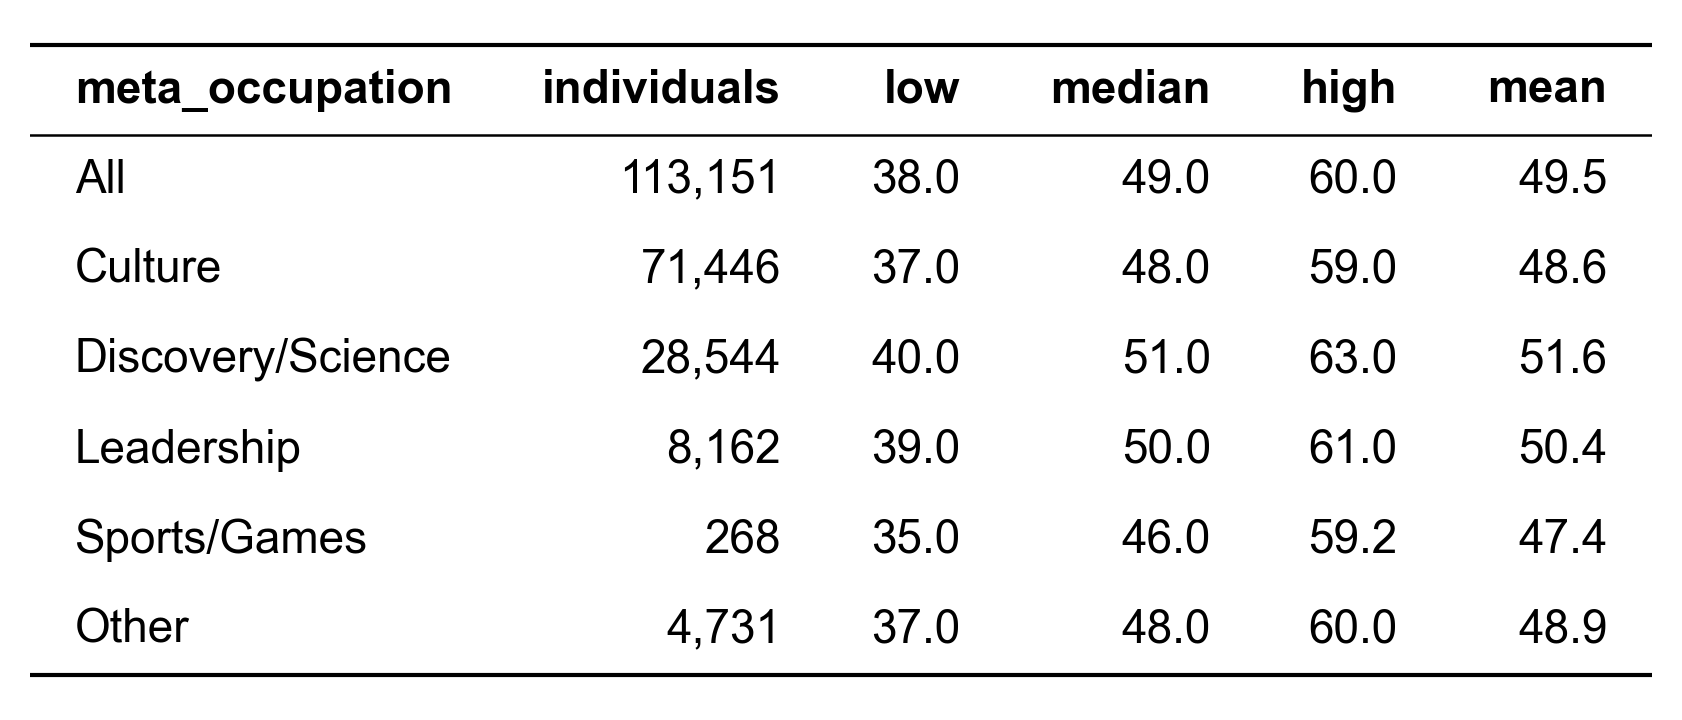

In [18]:
show_table(group_stats('last_age'), decimals=1)

### Figure: age at last work, all individuals and by meta occupation

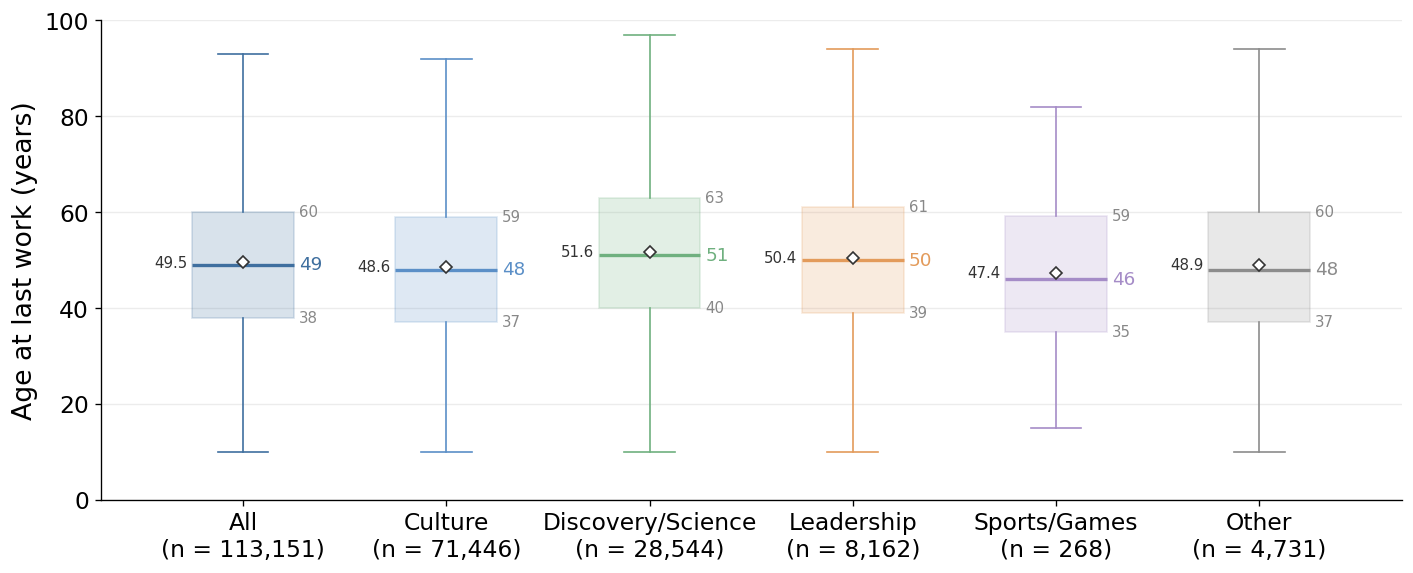

In [19]:
figure_groups('last')

### Table: age at last work per century of birth

In [20]:
box_stats(works, 'last_age', 'century')

century,individuals,low,median,high,mean
i64,u32,f64,f64,f64,f64
-500,11,53.5,58.0,72.0,60.7
-400,16,43.25,52.5,63.25,51.7
-100,16,41.5,51.0,58.25,51.4
0,16,47.5,54.5,62.0,51.8
100,14,37.0,46.0,62.25,50.2
200,15,35.0,41.0,54.0,44.0
300,27,36.5,45.0,57.0,47.7
400,16,36.75,46.5,54.5,48.2
500,36,44.75,54.5,63.75,53.7


### Figure: age at last work per century of birth
Individuals above each century; centuries with fewer than 10 individuals are left out.

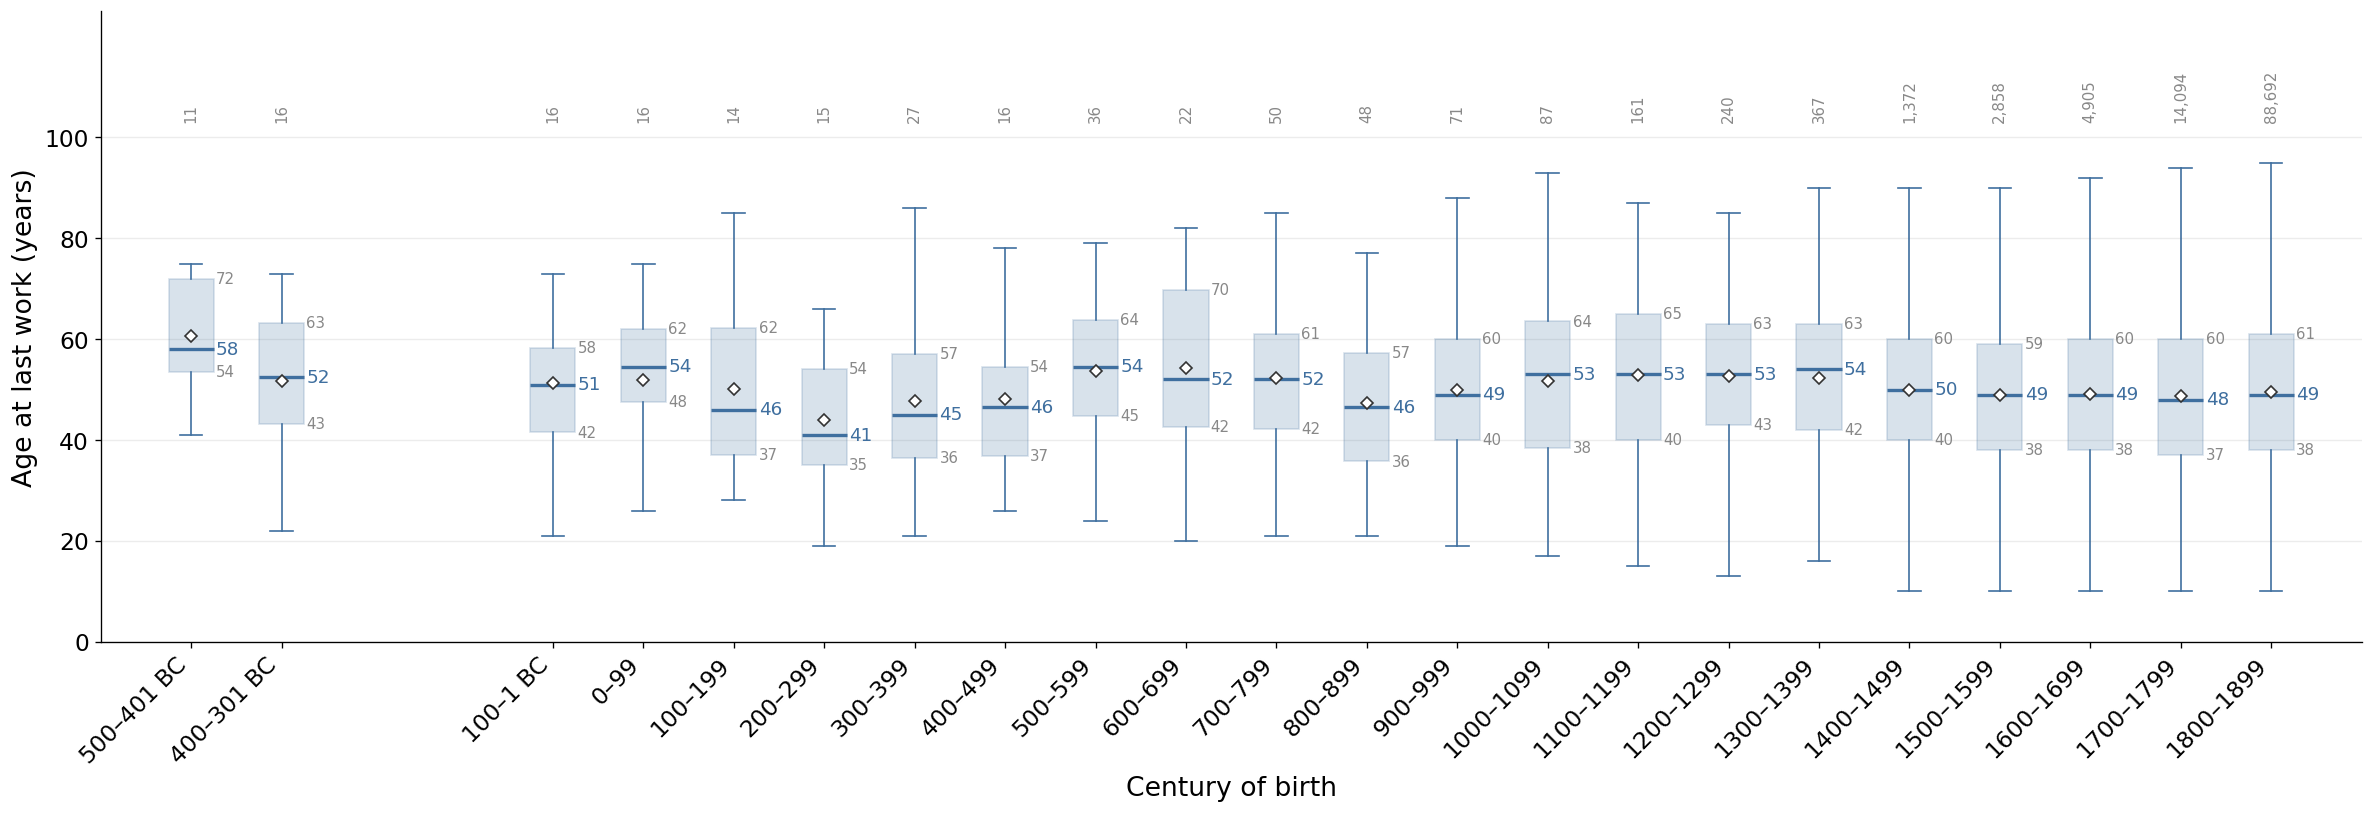

In [21]:
figure_centuries('last')

### Table: age at last work per century of birth and meta occupation
The values used by the century × meta occupation model.

In [22]:
box_stats(works.filter(pl.col('meta_occupation').is_in(list(OCCUPATION_COLORS))), 'last_age', ['meta_occupation', 'century'])

meta_occupation,century,individuals,low,median,high,mean
str,i64,u32,f64,f64,f64,f64
"""Culture""",500,12,36.5,54.0,61.25,50.2
"""Culture""",700,18,38.75,44.0,54.0,45.8
"""Culture""",800,10,36.0,44.5,46.5,44.4
"""Culture""",900,20,37.5,49.5,60.0,50.9
"""Culture""",1000,28,36.75,50.0,61.25,49.4
"""Culture""",1100,69,35.0,50.0,61.0,50.4
"""Culture""",1200,109,44.0,56.0,62.0,53.3
"""Culture""",1300,216,43.75,53.5,63.0,52.9
"""Culture""",1400,973,40.0,50.0,60.0,49.2


### Figure: age at last work per century of birth, by meta occupation

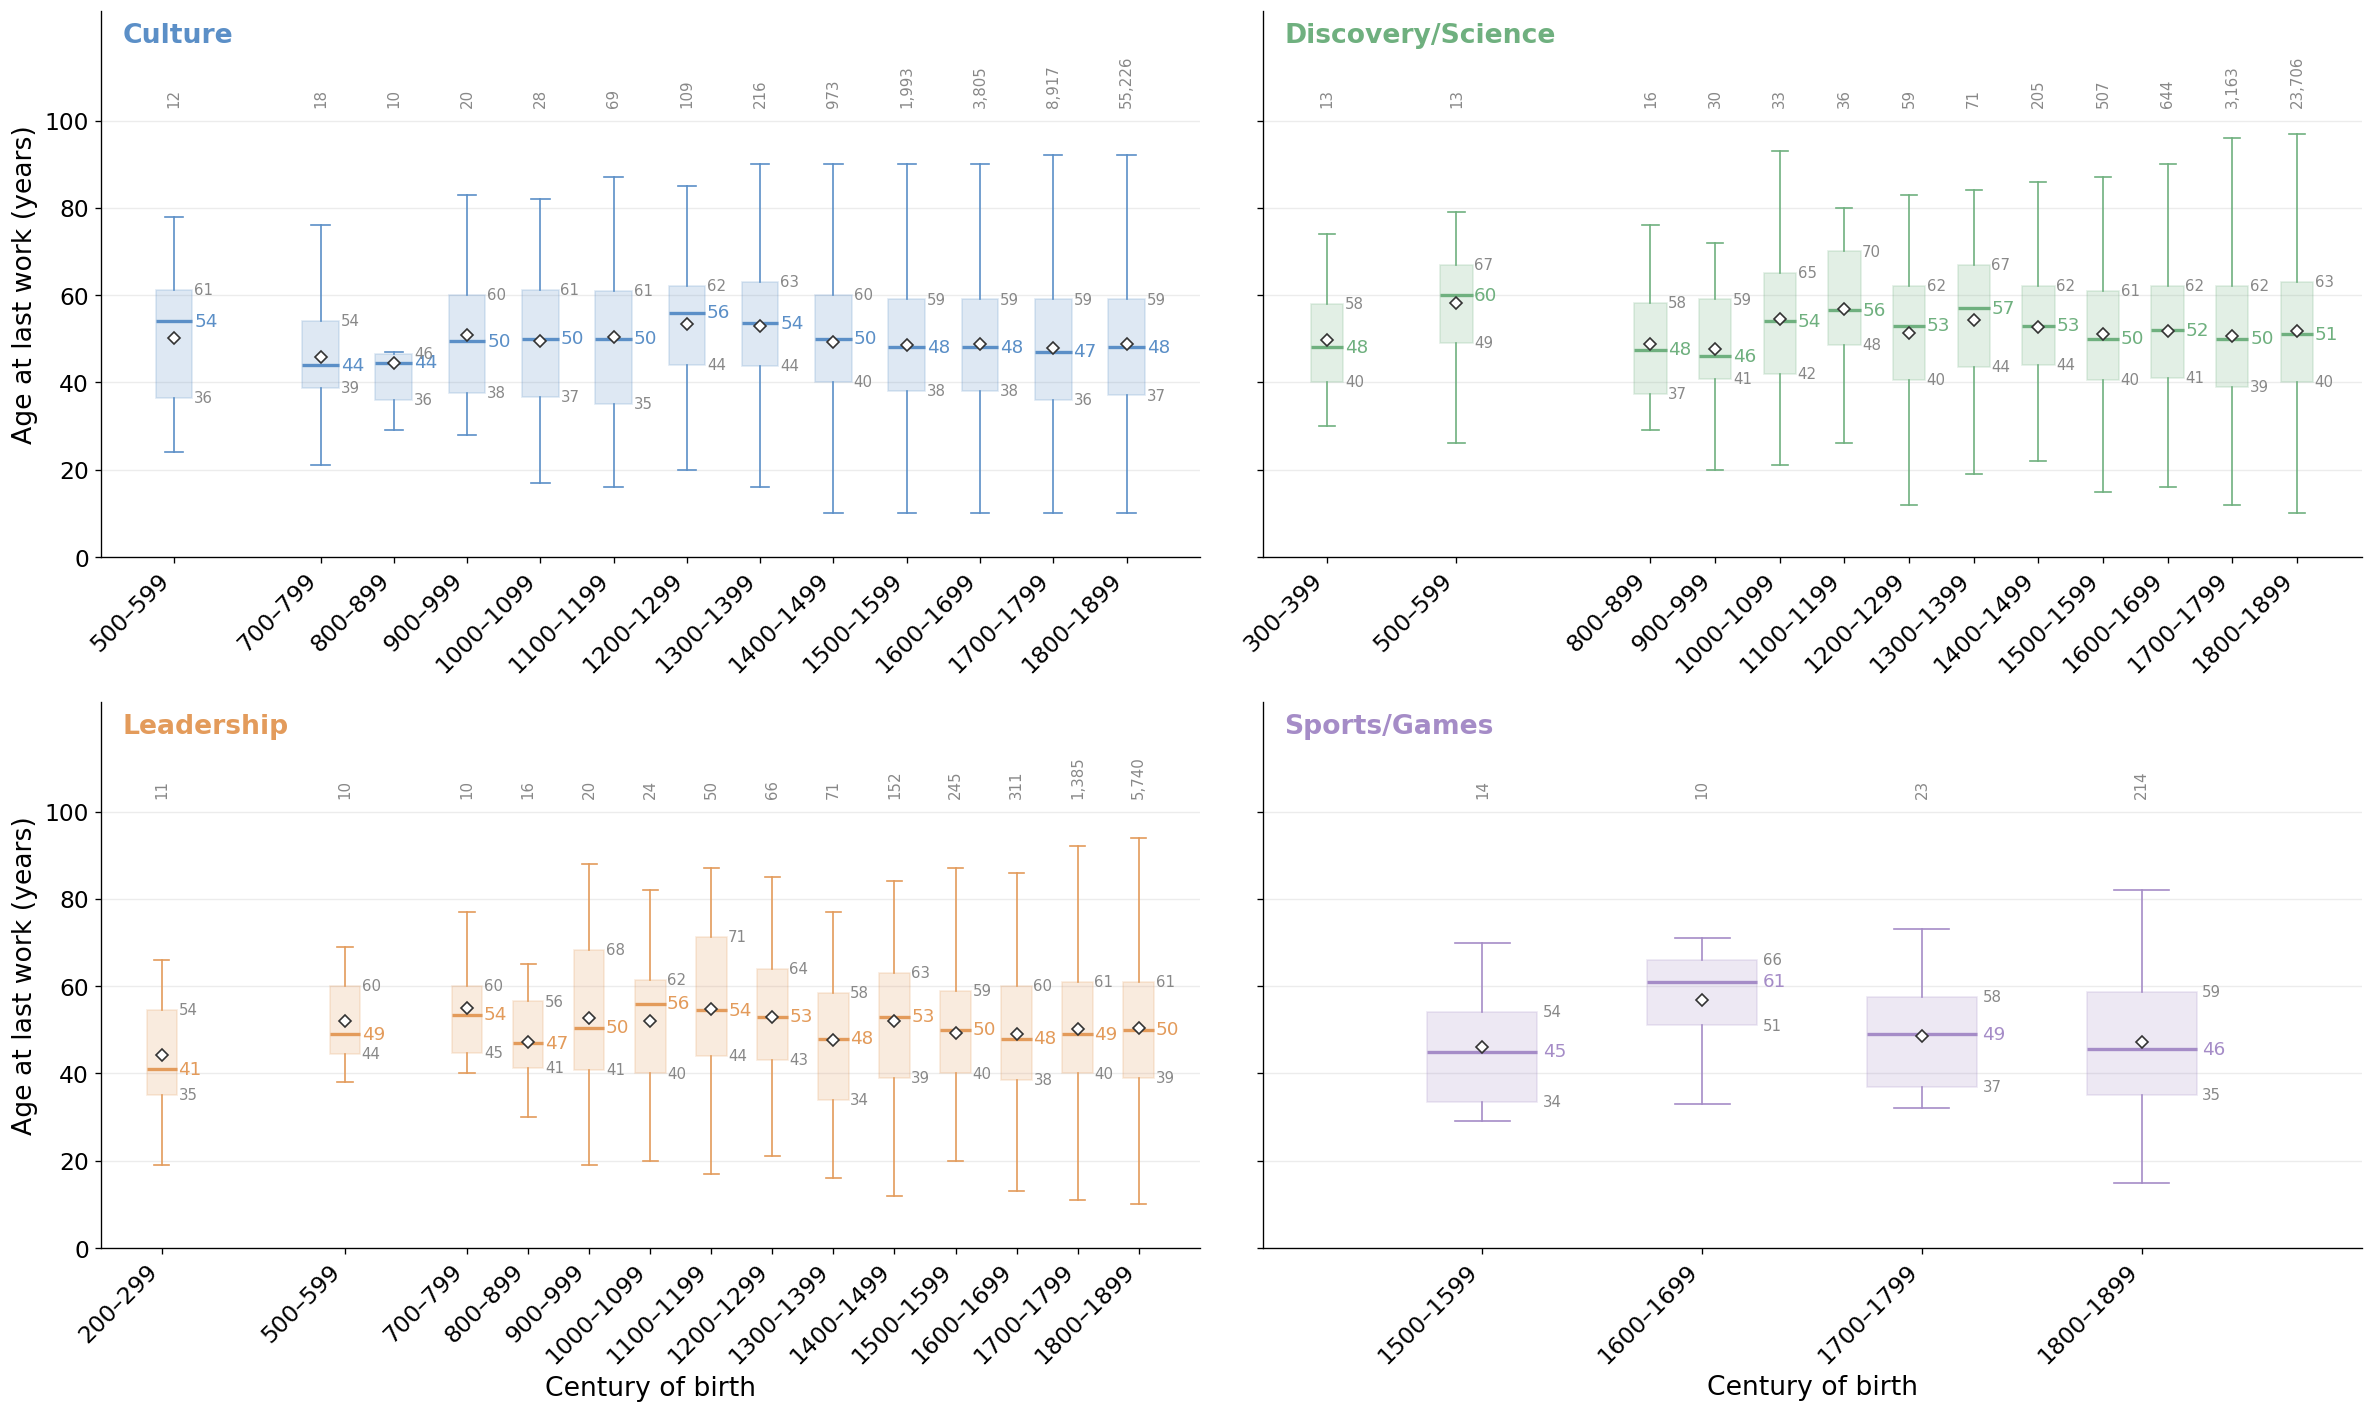

In [23]:
figure_occupation_centuries('last')

## 3. Average length of activity
Length of activity = age at last work − age at first work. On the same individuals, the mean length is exactly the mean age at last work minus the mean age at first work; the median length is not the difference of the medians. Individuals with a single cleaned work have a length of 0, so the table also shows those with at least 2 works.

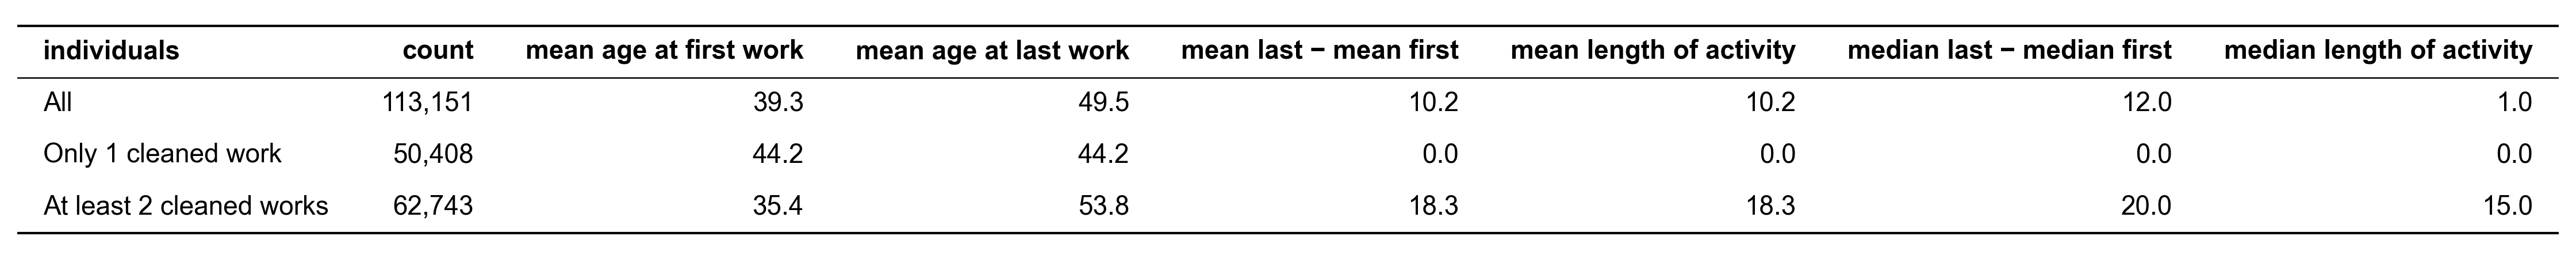

In [24]:
works = works.with_columns((pl.col('last_age') - pl.col('first_age')).alias('activity'))


def activity_row(name, frame):
    assert abs(frame['activity'].mean() - (frame['last_age'].mean() - frame['first_age'].mean())) < 1e-9
    return {
        'individuals': name,
        'count': frame.height,
        'mean age at first work': frame['first_age'].mean(),
        'mean age at last work': frame['last_age'].mean(),
        'mean last − mean first': frame['last_age'].mean() - frame['first_age'].mean(),
        'mean length of activity': frame['activity'].mean(),
        'median last − median first': frame['last_age'].median() - frame['first_age'].median(),
        'median length of activity': frame['activity'].median(),
    }


show_table(pl.DataFrame([
    activity_row('All', works),
    activity_row('Only 1 cleaned work', works.filter(pl.col('works') == 1)),
    activity_row('At least 2 cleaned works', works.filter(pl.col('works') >= 2)),
]), decimals=1)

### Table: length of activity of the individuals with at least 2 cleaned works, by meta occupation

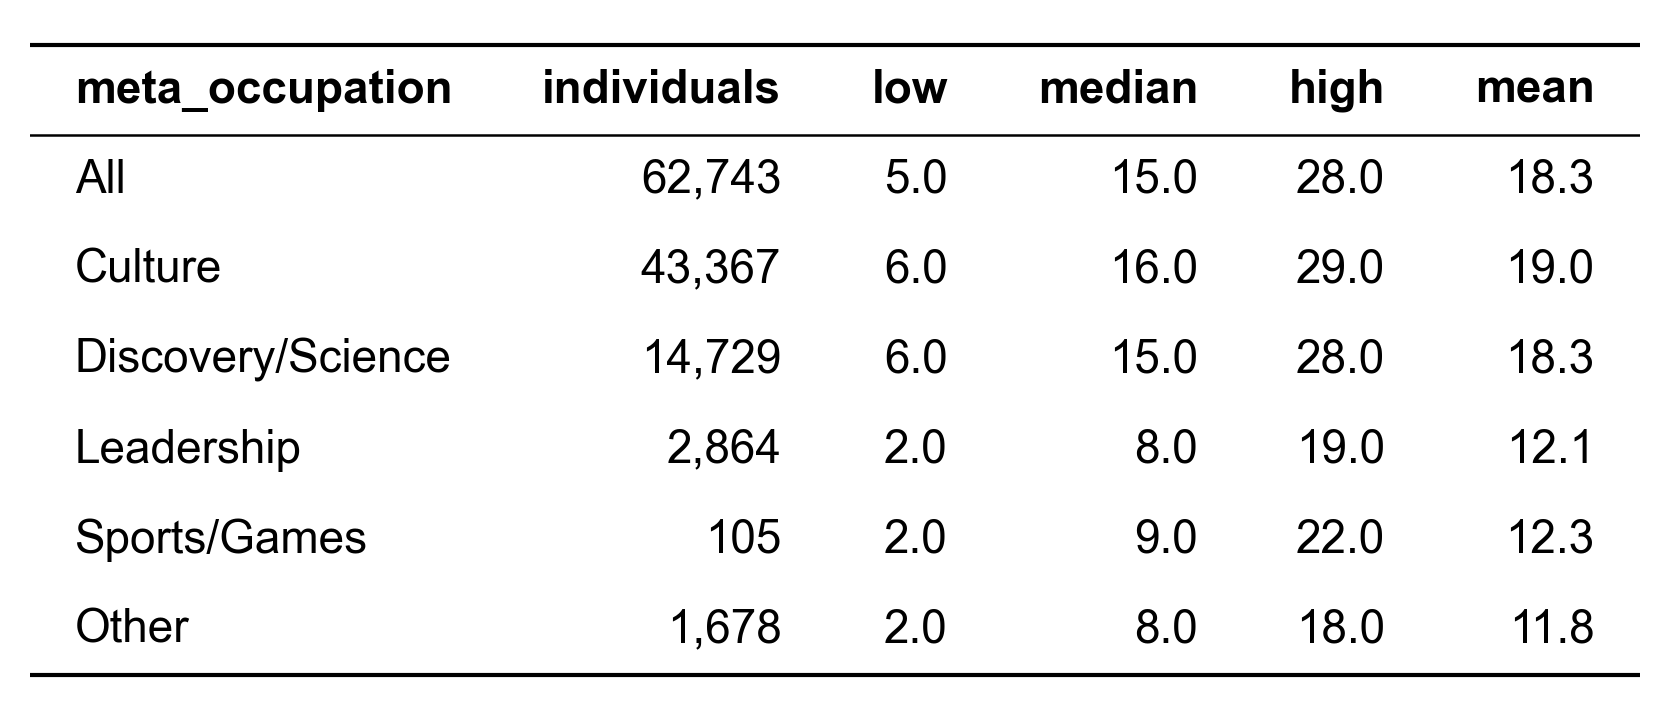

In [25]:
MEASURES['activity'] = {'label': 'activity'}
several = works.filter(pl.col('works') >= 2)
show_table(pl.concat([
    box_stats(several.with_columns(pl.lit('All').alias('meta_occupation')), 'activity', 'meta_occupation'),
    box_stats(several, 'activity', 'meta_occupation'),
]).sort(pl.col('meta_occupation').replace_strict(GROUPS, list(range(len(GROUPS))))), decimals=1)